In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/simuteh"
NOTEBOOK_DIR = os.path.join(PROJECT_DIR, "notebook")
SRC_DIR = os.path.join(PROJECT_DIR, "src")
DATA_DIR = os.path.join(PROJECT_DIR, "data", "sintetis")
HASIL_DIR = os.path.join(PROJECT_DIR, "hasil")

os.chdir(NOTEBOOK_DIR)

if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

from utils_cv import baca, tampil, kontras_bercak, statistik

print("Folder proyek:", PROJECT_DIR)
print("Notebook aktif:", os.getcwd())
print("Jumlah citra:", len(os.listdir(os.path.join(DATA_DIR, "citra"))))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder proyek: /content/drive/MyDrive/simuteh
Notebook aktif: /content/drive/MyDrive/simuteh/notebook
Jumlah citra: 60


In [2]:
# B4 - Fungsi Konvolusi Manual

def konvolusi(img, k):
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2

    # Padding menggunakan nilai piksel tepi
    pad = np.pad(
        img.astype(float),
        ((ph, ph), (pw, pw)),
        mode="edge"
    )

    out = np.zeros(img.shape)

    # Proses konvolusi manual
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(
                pad[y:y+kh, x:x+kw] * k
            )

    # Membatasi nilai piksel ke rentang 0-255
    return np.clip(np.round(out), 0, 255).astype(np.uint8)


print("Fungsi konvolusi manual berhasil dibuat.")

Fungsi konvolusi manual berhasil dibuat.


In [3]:
# Matriks citra sederhana untuk pengujian
P = np.array([
    [52, 55, 61, 58],
    [59, 255, 64, 60],
    [62, 60, 0, 57],
    [58, 61, 59, 63]
], dtype=np.uint8)

# Kernel mean 3x3
kernel_mean = np.ones((3, 3), dtype=np.float32) / 9

# Kernel Gaussian 3x3
kernel_gaussian = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32) / 16

# Kernel sharpening
kernel_sharpen = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

hasil_mean = konvolusi(P, kernel_mean)
hasil_gaussian = konvolusi(P, kernel_gaussian)
hasil_sharpen = konvolusi(P, kernel_sharpen)

print("Matriks P:")
print(P)

print("\nHasil filter Mean:")
print(hasil_mean)

print("\nHasil filter Gaussian:")
print(hasil_gaussian)

print("\nHasil filter Sharpening:")
print(hasil_sharpen)

Matriks P:
[[ 52  55  61  58]
 [ 59 255  64  60]
 [ 62  60   0  57]
 [ 58  61  59  63]]

Hasil filter Mean:
[[77 79 81 60]
 [80 74 74 53]
 [82 75 75 54]
 [60 53 54 54]]

Hasil filter Gaussian:
[[ 67  81  72  59]
 [ 83 104  77  56]
 [ 72  77  57  52]
 [ 59  56  53  57]]

Hasil filter Sharpening:
[[ 42   0  67  53]
 [  0 255   0  61]
 [ 71   0   0 105]
 [ 51  67 112  73]]


In [4]:
# B4 - Perbandingan Konvolusi Manual dan OpenCV

# Kernel simetris
kernel_mean = np.ones((3, 3), dtype=np.float32) / 9

# Kernel asimetris untuk menguji perbedaan orientasi
kernel_asimetris = np.array([
    [1,  0, -1],
    [2,  0, -2],
    [1,  0, -1]
], dtype=np.float32)

def bandingkan_konvolusi(img, kernel, nama_kernel):
    # Hasil fungsi konvolusi manual
    hasil_manual = konvolusi(img, kernel)

    # Hasil OpenCV
    hasil_opencv = cv2.filter2D(
        img,
        ddepth=-1,
        kernel=kernel,
        borderType=cv2.BORDER_REPLICATE
    )

    # Hitung selisih
    selisih = np.abs(
        hasil_manual.astype(np.int16) -
        hasil_opencv.astype(np.int16)
    )

    print(f"\n=== {nama_kernel} ===")
    print("Hasil manual:")
    print(hasil_manual)
    print("\nHasil cv2.filter2D:")
    print(hasil_opencv)
    print("\nSelisih maksimum:", selisih.max())
    print("Rata-rata selisih:", selisih.mean())

    return hasil_manual, hasil_opencv, selisih


hasil_mean_manual, hasil_mean_cv, selisih_mean = bandingkan_konvolusi(
    P, kernel_mean, "Kernel Mean Simetris"
)

hasil_asim_manual, hasil_asim_cv, selisih_asim = bandingkan_konvolusi(
    P, kernel_asimetris, "Kernel Asimetris"
)


=== Kernel Mean Simetris ===
Hasil manual:
[[77 79 81 60]
 [80 74 74 53]
 [82 75 75 54]
 [60 53 54 54]]

Hasil cv2.filter2D:
[[77 79 81 60]
 [80 74 74 53]
 [82 75 75 54]
 [60 53 54 54]]

Selisih maksimum: 0
Rata-rata selisih: 0.0

=== Kernel Asimetris ===
Hasil manual:
[[  0   0 186  13]
 [  0  43 255   0]
 [  0 118 199   0]
 [  0  59   0   0]]

Hasil cv2.filter2D:
[[  0   0 186  13]
 [  0  43 255   0]
 [  0 118 199   0]
 [  0  59   0   0]]

Selisih maksimum: 0
Rata-rata selisih: 0.0


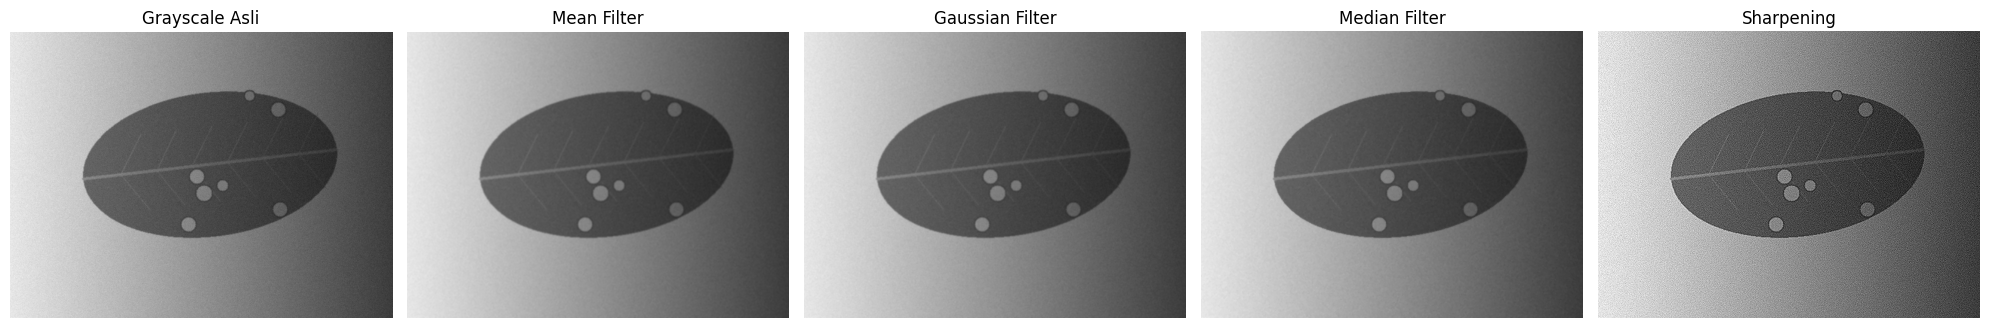

Gambar tersimpan: /content/drive/MyDrive/simuteh/hasil/b4_perbandingan_filter_teh_045.png


In [5]:
# B4 - Pengujian Filter pada Citra Daun Teh

nama_citra = "teh_045.png"
path_citra = os.path.join(DATA_DIR, "citra", nama_citra)

img_bgr = cv2.imread(path_citra)

if img_bgr is None:
    raise FileNotFoundError(f"Citra tidak ditemukan: {path_citra}")

# Konversi ke grayscale
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Terapkan filter
hasil_mean = cv2.filter2D(
    gray, -1, kernel_mean,
    borderType=cv2.BORDER_REPLICATE
)

hasil_gaussian = cv2.GaussianBlur(
    gray, (3, 3), 0,
    borderType=cv2.BORDER_REPLICATE
)

hasil_median = cv2.medianBlur(gray, 3)

hasil_sharpen = cv2.filter2D(
    gray, -1, kernel_sharpen,
    borderType=cv2.BORDER_REPLICATE
)

# Tampilkan perbandingan
judul = [
    "Grayscale Asli",
    "Mean Filter",
    "Gaussian Filter",
    "Median Filter",
    "Sharpening"
]

gambar = [
    gray,
    hasil_mean,
    hasil_gaussian,
    hasil_median,
    hasil_sharpen
]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, im, title in zip(axes, gambar, judul):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()

path_output = os.path.join(HASIL_DIR, "b4_perbandingan_filter_teh_045.png")
plt.savefig(path_output, dpi=150, bbox_inches="tight")
plt.show()

print("Gambar tersimpan:", path_output)

In [6]:
# B4 - Evaluasi Hasil Penapisan

# Membaca masker daun dan masker bercak
path_mask_daun = os.path.join(DATA_DIR, "mask_daun", nama_citra)
path_mask_bercak = os.path.join(DATA_DIR, "mask_bercak", nama_citra)

mask_daun = cv2.imread(path_mask_daun, cv2.IMREAD_GRAYSCALE)
mask_bercak = cv2.imread(path_mask_bercak, cv2.IMREAD_GRAYSCALE)

if mask_daun is None:
    raise FileNotFoundError(f"Masker daun tidak ditemukan: {path_mask_daun}")

if mask_bercak is None:
    raise FileNotFoundError(f"Masker bercak tidak ditemukan: {path_mask_bercak}")

# Daftar citra yang akan dibandingkan
daftar_hasil = {
    "Asli": gray,
    "Mean": hasil_mean,
    "Gaussian": hasil_gaussian,
    "Median": hasil_median,
    "Sharpening": hasil_sharpen
}

baris = []

for nama_filter, citra in daftar_hasil.items():
    nilai_kb = kontras_bercak(citra, mask_daun, mask_bercak)

    baris.append({
        "Filter": nama_filter,
        "Rata-rata intensitas": float(np.mean(citra)),
        "Standar deviasi": float(np.std(citra)),
        "KB": float(nilai_kb)
    })

tabel_evaluasi = pd.DataFrame(baris)

display(tabel_evaluasi.round(4))

# Simpan tabel evaluasi
path_csv = os.path.join(HASIL_DIR, "b4_evaluasi_filter_teh_045.csv")
tabel_evaluasi.to_csv(path_csv, index=False)

print("Tabel evaluasi tersimpan:", path_csv)

,Filter,Rata-rata intensitas,Standar deviasi,KB
0,Asli,127.8129,57.8579,1.6131
1,Mean,127.8136,57.6279,1.6747
2,Gaussian,127.8446,57.6453,1.6736
3,Median,127.8087,57.6734,1.6906
4,Sharpening,127.6505,63.0336,0.8643


Tabel evaluasi tersimpan: /content/drive/MyDrive/simuteh/hasil/b4_evaluasi_filter_teh_045.csv


In [7]:
import inspect
print(inspect.getsource(kontras_bercak))

def kontras_bercak(kanal, mask_daun, mask_bercak):
    """Mengukur kontras bercak terhadap bagian daun sehat."""
    k = kanal.astype(np.float64)

    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0

    if bercak.sum() == 0:
        return float("nan")

    return abs(
        k[bercak].mean() - k[sehat].mean()
    ) / (k[sehat].std() + 1e-6)



In [8]:
# B4 - Langkah 4.3: Persiapan Citra Pengujian

nama = "teh_041.png"

path_bersih = os.path.join(DATA_DIR, "bersih", nama)
path_mask_daun = os.path.join(DATA_DIR, "mask_daun", nama)
path_mask_bercak = os.path.join(DATA_DIR, "mask_bercak", nama)

img_bersih_bgr = cv2.imread(path_bersih)
mask_daun_uji = cv2.imread(path_mask_daun, cv2.IMREAD_GRAYSCALE)
mask_bercak_uji = cv2.imread(path_mask_bercak, cv2.IMREAD_GRAYSCALE)

if img_bersih_bgr is None:
    raise FileNotFoundError(f"Citra bersih tidak ditemukan: {path_bersih}")

if mask_daun_uji is None:
    raise FileNotFoundError(f"Masker daun tidak ditemukan: {path_mask_daun}")

if mask_bercak_uji is None:
    raise FileNotFoundError(f"Masker bercak tidak ditemukan: {path_mask_bercak}")

bersih = cv2.cvtColor(img_bersih_bgr, cv2.COLOR_BGR2GRAY)

print("Citra pengujian:", nama)
print("Ukuran citra:", bersih.shape)
print("Piksel masker daun:", int(np.sum(mask_daun_uji > 0)))
print("Piksel masker bercak:", int(np.sum(mask_bercak_uji > 0)))
print("Persiapan selesai.")

Citra pengujian: teh_041.png
Ukuran citra: (480, 640)
Piksel masker daun: 65724
Piksel masker bercak: 3836
Persiapan selesai.


In [9]:
# B4 - Langkah 4.3: Pembangkit Derau dan Enam Penapis

# Seed agar hasil eksperimen dapat direproduksi
rng = np.random.default_rng(42)

# 1. Pembangkit derau Gaussian
def derau_gauss(img, sd):
    noise = rng.normal(0, sd, img.shape)
    return np.clip(img.astype(float) + noise, 0, 255).astype(np.uint8)


# 2. Pembangkit derau garam-merica
def derau_sp(img, p):
    out = img.copy()
    m = rng.random(img.shape)
    out[m < p / 2] = 0
    out[m > 1 - p / 2] = 255
    return out


# 3. Enam penapis
def filter_mean(img):
    return cv2.blur(
        img, (3, 3),
        borderType=cv2.BORDER_REPLICATE
    )


def filter_gaussian(img):
    return cv2.GaussianBlur(
        img, (3, 3), 0,
        borderType=cv2.BORDER_REPLICATE
    )


def filter_median3(img):
    return cv2.medianBlur(img, 3)


def filter_median5(img):
    return cv2.medianBlur(img, 5)


def filter_median7(img):
    return cv2.medianBlur(img, 7)


def filter_bilateral(img):
    return cv2.bilateralFilter(
        img, 5, 25, 25,
        borderType=cv2.BORDER_REPLICATE
    )


penapis = {
    "Mean 3x3": filter_mean,
    "Gaussian 3x3": filter_gaussian,
    "Median 3x3": filter_median3,
    "Median 5x5": filter_median5,
    "Median 7x7": filter_median7,
    "Bilateral": filter_bilateral
}

print("Pembangkit derau berhasil dibuat.")
print("Jumlah penapis:", len(penapis))
print("Nama penapis:", list(penapis.keys()))

Pembangkit derau berhasil dibuat.
Jumlah penapis: 6
Nama penapis: ['Mean 3x3', 'Gaussian 3x3', 'Median 3x3', 'Median 5x5', 'Median 7x7', 'Bilateral']


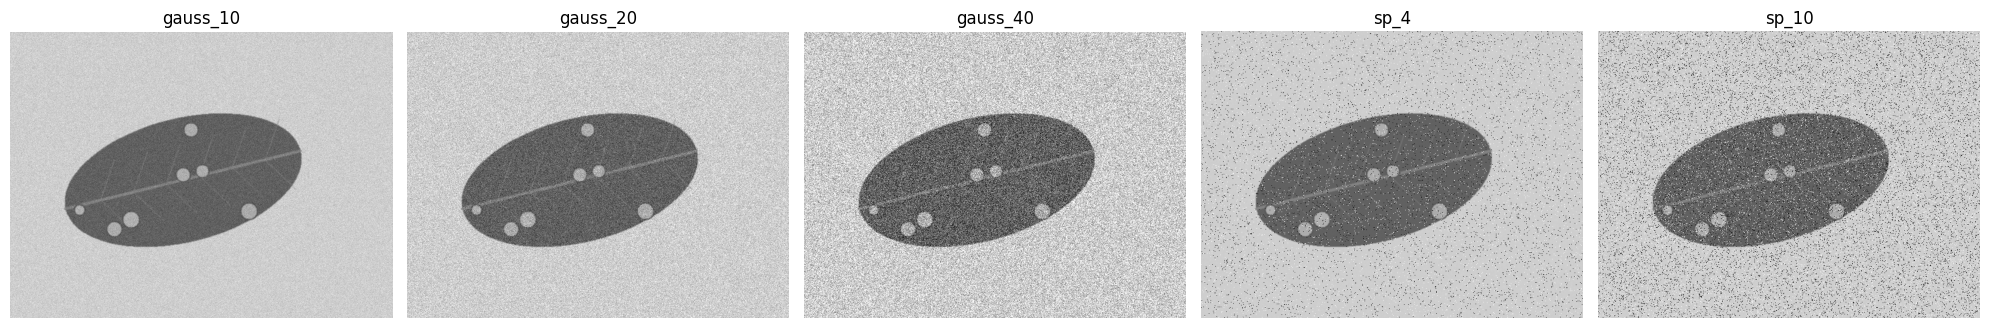

Jumlah variasi derau: 5
Jumlah penapis: 6
Total kombinasi pengujian: 30


In [10]:
# B4 - Uji Derau dan Penapis

# Bangkitkan lima variasi derau
derau = {
    "gauss_10": derau_gauss(bersih, 10),
    "gauss_20": derau_gauss(bersih, 20),
    "gauss_40": derau_gauss(bersih, 40),
    "sp_4": derau_sp(bersih, 0.04),
    "sp_10": derau_sp(bersih, 0.10)
}

# Tampilkan contoh citra dengan derau
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, (nama_derau, citra) in zip(axes, derau.items()):
    ax.imshow(citra, cmap="gray", vmin=0, vmax=255)
    ax.set_title(nama_derau)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Jumlah variasi derau:", len(derau))
print("Jumlah penapis:", len(penapis))
print("Total kombinasi pengujian:", len(derau) * len(penapis))

In [11]:
# B4 - Daftar enam penapis sesuai Kode 4.2 pada PDF

penapis = {
    "rerata_3": lambda x: cv2.blur(x, (3, 3)),
    "rerata_5": lambda x: cv2.blur(x, (5, 5)),
    "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "median_3": lambda x: cv2.medianBlur(x, 3),
    "median_5": lambda x: cv2.medianBlur(x, 5),
    "median_9": lambda x: cv2.medianBlur(x, 9)
}

print("Jumlah variasi derau:", len(derau))
print("Jumlah penapis:", len(penapis))
print("Nama penapis:", list(penapis.keys()))
print("Total kombinasi pengujian:", len(derau) * len(penapis))


Jumlah variasi derau: 5
Jumlah penapis: 6
Nama penapis: ['rerata_3', 'rerata_5', 'gauss_5', 'median_3', 'median_5', 'median_9']
Total kombinasi pengujian: 30


In [12]:
# B4 - Kode 4.2: Tabel penapis x derau x PSNR x waktu x KB

import pandas as pd
import time
import cv2
import numpy as np
import os

def ukur_waktu(f, x, ulang=20):
    waktu = []
    for _ in range(ulang):
        t0 = time.perf_counter()
        f(x)
        waktu.append(time.perf_counter() - t0)
    return 1000 * np.mean(waktu)

baris = []

for nama_derau, citra_derau in derau.items():
    # Data tanpa penapisan
    baris.append([
        nama_derau,
        "tanpa",
        cv2.PSNR(bersih, citra_derau),
        0.0,
        kontras_bercak(citra_derau, mask_daun_uji, mask_bercak_uji)
    ])

    # Data setelah setiap penapis
    for nama_penapis, fungsi in penapis.items():
        hasil_filter = fungsi(citra_derau)

        psnr = cv2.PSNR(bersih, hasil_filter)
        waktu_ms = ukur_waktu(fungsi, citra_derau)
        kb = kontras_bercak(
            hasil_filter,
            mask_daun_uji,
            mask_bercak_uji
        )

        baris.append([
            nama_derau,
            nama_penapis,
            psnr,
            waktu_ms,
            kb
        ])

tabel = pd.DataFrame(
    baris,
    columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]
).round(2)

display(tabel)

# Simpan hasil ke folder hasil
os.makedirs(HASIL_DIR, exist_ok=True)
path_csv = os.path.join(HASIL_DIR, "b4_tabel_penapis.csv")
tabel.to_csv(path_csv, index=False)

print("\nJumlah baris hasil:", len(tabel))
print("File tersimpan:", path_csv)


,derau,penapis,PSNR_dB,waktu_ms,KB
0,gauss_10,tanpa,28.11,0.00,4.30
1,gauss_10,rerata_3,36.81,0.39,6.78
2,gauss_10,rerata_5,37.34,0.25,6.66
3,gauss_10,gauss_5,37.60,0.51,6.92
4,gauss_10,median_3,35.49,0.14,6.89
5,gauss_10,median_5,38.52,1.27,7.90
6,gauss_10,median_9,39.17,27.47,8.67
7,gauss_20,tanpa,22.15,0.00,2.43
8,gauss_20,rerata_3,31.44,0.21,5.38
9,gauss_20,rerata_5,34.33,0.25,6.06



Jumlah baris hasil: 35
File tersimpan: /content/drive/MyDrive/simuteh/hasil/b4_tabel_penapis.csv


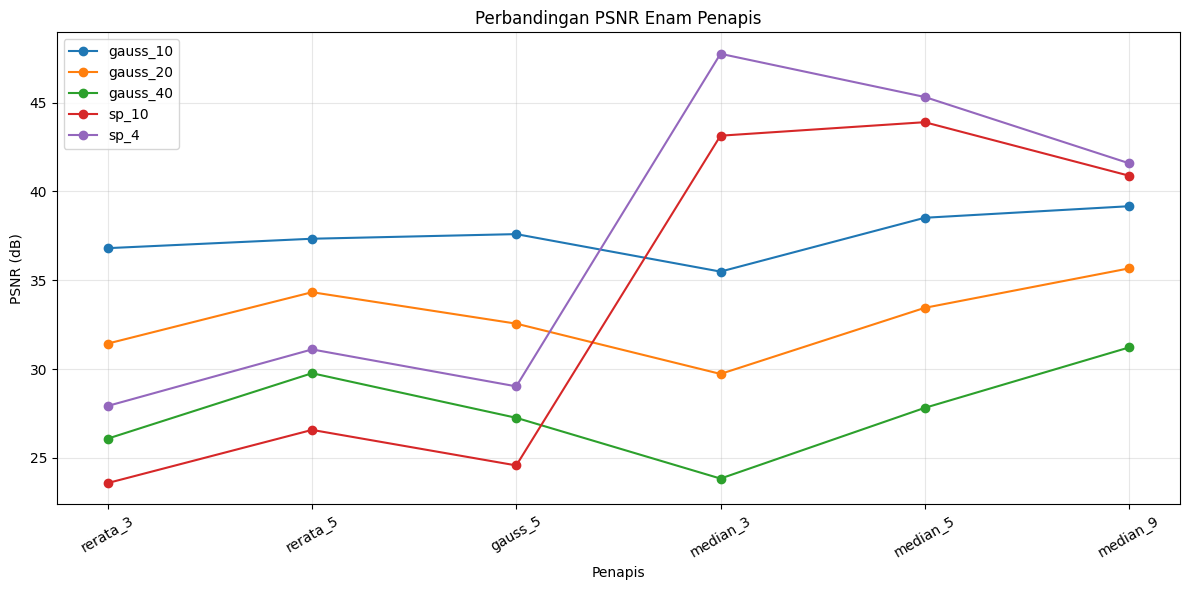

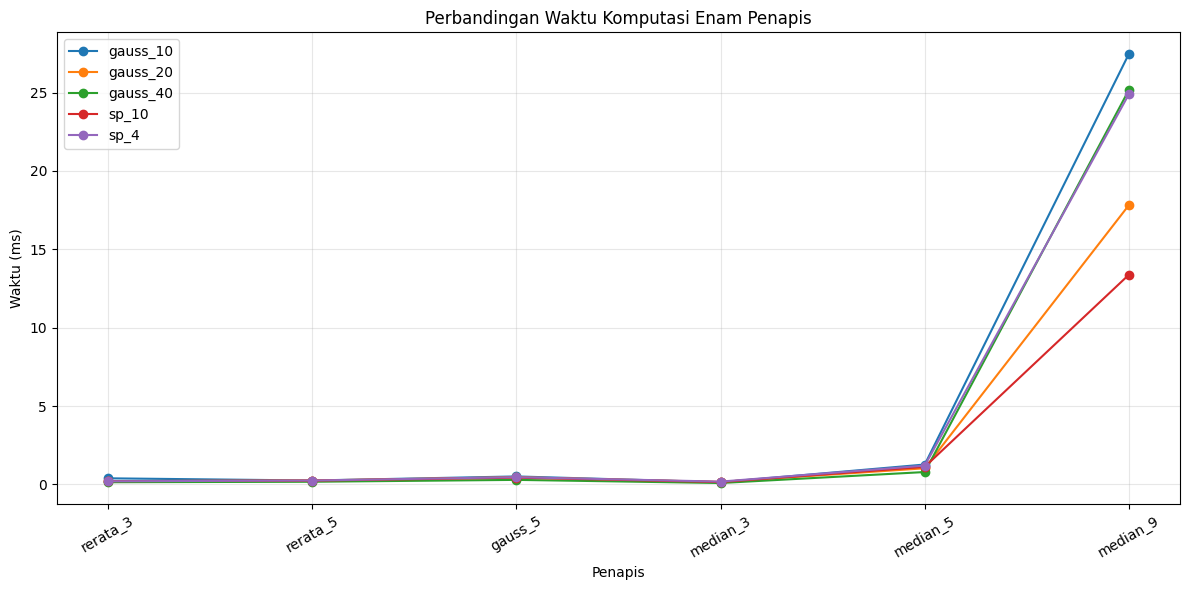

Grafik PSNR tersimpan: /content/drive/MyDrive/simuteh/hasil/b4_grafik_psnr.png
Grafik waktu tersimpan: /content/drive/MyDrive/simuteh/hasil/b4_grafik_waktu.png


In [13]:
# B4 - Grafik PSNR dan waktu komputasi

import matplotlib.pyplot as plt
import os

# Baca tabel hasil yang sudah disimpan
tabel = pd.read_csv(
    os.path.join(HASIL_DIR, "b4_tabel_penapis.csv")
)

# Pisahkan hasil tanpa penapis dan hasil dengan penapis
tabel_filter = tabel[tabel["penapis"] != "tanpa"].copy()

# Grafik PSNR
plt.figure(figsize=(12, 6))

for nama_derau, grup in tabel_filter.groupby("derau"):
    plt.plot(
        grup["penapis"],
        grup["PSNR_dB"],
        marker="o",
        label=nama_derau
    )

plt.title("Perbandingan PSNR Enam Penapis")
plt.xlabel("Penapis")
plt.ylabel("PSNR (dB)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()

path_psnr = os.path.join(HASIL_DIR, "b4_grafik_psnr.png")
plt.savefig(path_psnr, dpi=200, bbox_inches="tight")
plt.show()

# Grafik waktu komputasi
plt.figure(figsize=(12, 6))

for nama_derau, grup in tabel_filter.groupby("derau"):
    plt.plot(
        grup["penapis"],
        grup["waktu_ms"],
        marker="o",
        label=nama_derau
    )

plt.title("Perbandingan Waktu Komputasi Enam Penapis")
plt.xlabel("Penapis")
plt.ylabel("Waktu (ms)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()

path_waktu = os.path.join(HASIL_DIR, "b4_grafik_waktu.png")
plt.savefig(path_waktu, dpi=200, bbox_inches="tight")
plt.show()

print("Grafik PSNR tersimpan:", path_psnr)
print("Grafik waktu tersimpan:", path_waktu)

In [14]:
# B4.4 - Pengaruh ukuran kernel median terhadap dI dan KB

def selisih_rerata(kanal, mask_daun, mask_bercak):
    """Menghitung selisih rerata intensitas bercak dan daun sehat."""
    k = kanal.astype(float)

    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0

    return abs(k[bercak].mean() - k[sehat].mean())


# Baca label dataset
label = pd.read_csv(
    os.path.join(DATA_DIR, "label.csv")
)

baris = []

# Ambil 20 citra kelas ringan
for nm in label[label["kelas"] == "ringan"]["nama_file"]:

    path = os.path.join(DATA_DIR, "bersih", nm)
    path_md = os.path.join(DATA_DIR, "mask_daun", nm)
    path_mb = os.path.join(DATA_DIR, "mask_bercak", nm)

    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    md = cv2.imread(path_md, cv2.IMREAD_GRAYSCALE)
    mb = cv2.imread(path_mb, cv2.IMREAD_GRAYSCALE)

    # Uji kernel median sesuai petunjuk praktikum
    for k in [1, 3, 5, 9, 15]:

        if k == 1:
            hasil = gray
        else:
            hasil = cv2.medianBlur(gray, k)

        dI = selisih_rerata(hasil, md, mb)
        KB = kontras_bercak(hasil, md, mb)

        baris.append([nm, k, dI, KB])


hasil_median = pd.DataFrame(
    baris,
    columns=["nama", "kernel", "dI", "KB"]
)

# Tampilkan rata-rata untuk setiap ukuran kernel
ringkasan_median = (
    hasil_median
    .groupby("kernel")[["dI", "KB"]]
    .mean()
    .round(2)
)

print("Jumlah citra kelas ringan:",
      label[label["kelas"] == "ringan"].shape[0])

print("\nRata-rata dI dan KB berdasarkan ukuran kernel:")
display(ringkasan_median)

Jumlah citra kelas ringan: 20

Rata-rata dI dan KB berdasarkan ukuran kernel:


,dI,KB
kernel,,
1,26.71,4.28
3,27.10,4.41
5,25.95,4.28
9,19.12,3.64
15,7.06,1.97


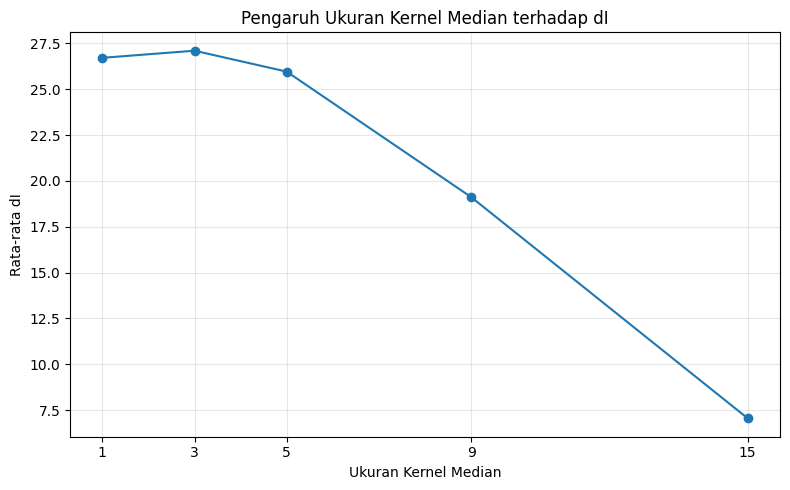

Grafik dI tersimpan: /content/drive/MyDrive/simuteh/hasil/b4_grafik_di_kernel_median.png
Ringkasan tersimpan: /content/drive/MyDrive/simuteh/hasil/b4_ringkasan_kernel_median.csv


In [15]:
# B4.4 - Grafik dI terhadap ukuran kernel median

import matplotlib.pyplot as plt

# Rata-rata dI setiap ukuran kernel
ringkasan_median = (
    hasil_median
    .groupby("kernel")[["dI", "KB"]]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))
plt.plot(
    ringkasan_median["kernel"],
    ringkasan_median["dI"],
    marker="o"
)

plt.title("Pengaruh Ukuran Kernel Median terhadap dI")
plt.xlabel("Ukuran Kernel Median")
plt.ylabel("Rata-rata dI")
plt.xticks([1, 3, 5, 9, 15])
plt.grid(True, alpha=0.3)
plt.tight_layout()

path_grafik_di = os.path.join(
    HASIL_DIR,
    "b4_grafik_di_kernel_median.png"
)

plt.savefig(path_grafik_di, dpi=200, bbox_inches="tight")
plt.show()

# Simpan ringkasan hasil pengukuran
path_csv_median = os.path.join(
    HASIL_DIR,
    "b4_ringkasan_kernel_median.csv"
)

ringkasan_median.to_csv(path_csv_median, index=False)

print("Grafik dI tersimpan:", path_grafik_di)
print("Ringkasan tersimpan:", path_csv_median)

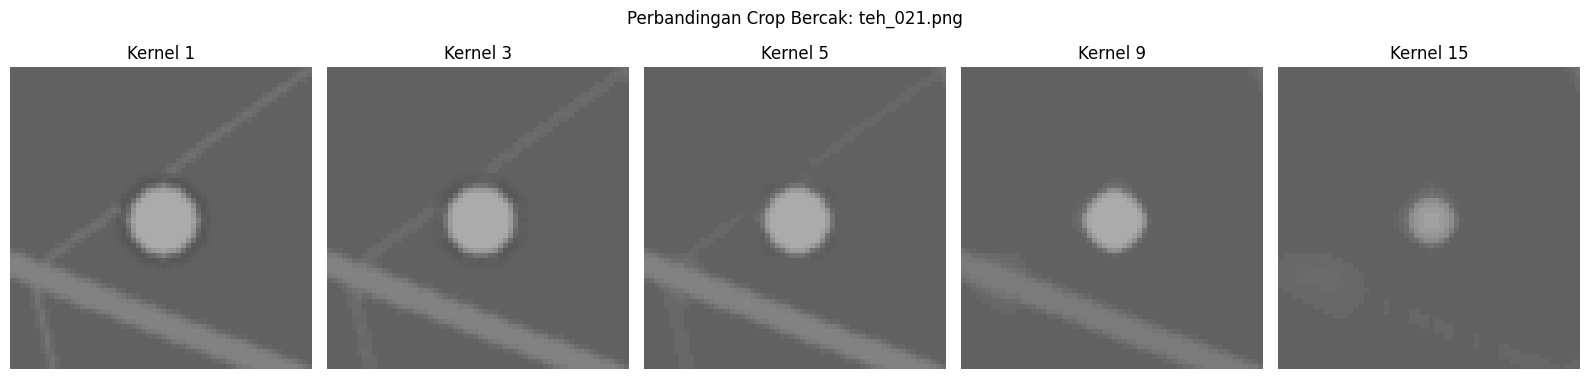

Crop perbandingan tersimpan: /content/drive/MyDrive/simuteh/hasil/b4_crop_perbandingan_median.png


In [16]:
# B4.4 - Perbandingan visual bercak setelah median filtering

# Gunakan satu citra kelas ringan
nama_crop = "teh_021.png"

img_path = os.path.join(DATA_DIR, "bersih", nama_crop)
img_bgr = cv2.imread(img_path)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

mask_path = os.path.join(DATA_DIR, "mask_bercak", nama_crop)
mask_bercak = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

# Cari lokasi bercak dari mask
y, x = np.where(mask_bercak > 0)

if len(x) == 0:
    print("Bercak tidak ditemukan pada citra ini.")
else:
    # Ambil bagian tengah bercak untuk crop
    cx = int(np.mean(x))
    cy = int(np.mean(y))

    # Ukuran area crop
    ukuran = 60
    x1 = max(0, cx - ukuran // 2)
    x2 = min(img_gray.shape[1], cx + ukuran // 2)
    y1 = max(0, cy - ukuran // 2)
    y2 = min(img_gray.shape[0], cy + ukuran // 2)

    crop_asli = img_gray[y1:y2, x1:x2]

    # Bandingkan kernel median
    kernel_list = [1, 3, 5, 9, 15]

    fig, axes = plt.subplots(1, len(kernel_list), figsize=(16, 4))

    for ax, k in zip(axes, kernel_list):
        if k == 1:
            crop_hasil = crop_asli
        else:
            hasil_penuh = cv2.medianBlur(img_gray, k)
            crop_hasil = hasil_penuh[y1:y2, x1:x2]

        ax.imshow(crop_hasil, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"Kernel {k}")
        ax.axis("off")

    plt.suptitle(f"Perbandingan Crop Bercak: {nama_crop}")
    plt.tight_layout()

    path_crop = os.path.join(
        HASIL_DIR,
        "b4_crop_perbandingan_median.png"
    )

    plt.savefig(path_crop, dpi=200, bbox_inches="tight")
    plt.show()

    print("Crop perbandingan tersimpan:", path_crop)

In [17]:
# B4.5 - Perbandingan urutan penajaman dan peredaman derau

def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)


# Gunakan citra dengan derau Gaussian sigma 20
noisy = derau["gauss_20"]

# Area latar di luar daun
latar = mask_daun_uji == 0

# Dua metode peredaman derau
metode_redam = {
    "Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "Median": lambda x: cv2.medianBlur(x, 5)
}

for nama, redam in metode_redam.items():

    # Penajaman terlebih dahulu, lalu peredaman
    A = redam(unsharp(noisy))

    # Peredaman terlebih dahulu, lalu penajaman
    B = unsharp(redam(noisy))

    print(
        f"{nama}: "
        f"tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
        f"sigma_latar={A[latar].std():.1f} | "
        f"redam->tajam PSNR={cv2.PSNR(bersih, B):.2f} "
        f"sigma_latar={B[latar].std():.1f}"
    )

Gaussian: tajam->redam PSNR=30.42 sigma_latar=7.7 | redam->tajam PSNR=30.22 sigma_latar=8.2
Median: tajam->redam PSNR=30.15 sigma_latar=8.1 | redam->tajam PSNR=31.10 sigma_latar=7.2


In [18]:
# B4.6 - Evaluasi filter pada 12 citra pencahayaan normal

nomor_citra = range(1, 57, 5)

# Filter pilihan untuk evaluasi
filter_pilihan = {
    "rerata_3": lambda x: cv2.blur(x, (3, 3)),
    "median_3": lambda x: cv2.medianBlur(x, 3),
    "median_5": lambda x: cv2.medianBlur(x, 5)
}

baris_b46 = []

for nomor in nomor_citra:
    nama = f"teh_{nomor:03d}.png"

    path_asli = os.path.join(DATA_DIR, "bersih", nama)
    path_citra = os.path.join(DATA_DIR, "citra", nama)

    img_asli = cv2.imread(path_asli)
    img_citra = cv2.imread(path_citra)

    if img_asli is None or img_citra is None:
        print("Citra tidak ditemukan:", nama)
        continue

    asli = cv2.cvtColor(img_asli, cv2.COLOR_BGR2GRAY)
    citra = cv2.cvtColor(img_citra, cv2.COLOR_BGR2GRAY)

    psnr_sebelum = cv2.PSNR(asli, citra)

    for nama_filter, fungsi in filter_pilihan.items():
        hasil = fungsi(citra)
        psnr_sesudah = cv2.PSNR(asli, hasil)

        baris_b46.append([
            nama,
            nama_filter,
            round(psnr_sebelum, 2),
            round(psnr_sesudah, 2)
        ])

tabel_b46 = pd.DataFrame(
    baris_b46,
    columns=[
        "nama_citra",
        "filter",
        "PSNR_sebelum_dB",
        "PSNR_sesudah_dB"
    ]
)

display(tabel_b46)

path_b46 = os.path.join(
    HASIL_DIR,
    "b4_evaluasi_12_citra_normal.csv"
)

tabel_b46.to_csv(path_b46, index=False)

print("Jumlah citra yang diuji:", tabel_b46["nama_citra"].nunique())
print("Hasil tersimpan:", path_b46)

,nama_citra,filter,PSNR_sebelum_dB,PSNR_sesudah_dB
0,teh_001.png,rerata_3,31.78,40.21
1,teh_001.png,median_3,31.78,39.01
2,teh_001.png,median_5,31.78,41.65
3,teh_006.png,rerata_3,28.78,37.69
4,teh_006.png,median_3,28.78,36.26
5,teh_006.png,median_5,28.78,39.45
6,teh_011.png,rerata_3,31.56,39.75
7,teh_011.png,median_3,31.56,38.77
8,teh_011.png,median_5,31.56,41.38
9,teh_016.png,rerata_3,30.79,39.23


Jumlah citra yang diuji: 12
Hasil tersimpan: /content/drive/MyDrive/simuteh/hasil/b4_evaluasi_12_citra_normal.csv


In [19]:
# Pemeriksaan kelengkapan file hasil B4

file_b4 = [
    "b4_tabel_penapis.csv",
    "b4_grafik_psnr.png",
    "b4_grafik_waktu.png",
    "b4_ringkasan_kernel_median.csv",
    "b4_grafik_di_kernel_median.png",
    "b4_crop_perbandingan_median.png",
    "b4_evaluasi_12_citra_normal.csv"
]

print("PEMERIKSAAN FILE HASIL B4\n")

for nama in file_b4:
    path = os.path.join(HASIL_DIR, nama)
    status = "ADA" if os.path.isfile(path) else "BELUM ADA"
    print(f"{nama}: {status}")

PEMERIKSAAN FILE HASIL B4

b4_tabel_penapis.csv: ADA
b4_grafik_psnr.png: ADA
b4_grafik_waktu.png: ADA
b4_ringkasan_kernel_median.csv: ADA
b4_grafik_di_kernel_median.png: ADA
b4_crop_perbandingan_median.png: ADA
b4_evaluasi_12_citra_normal.csv: ADA


In [20]:
# B4.2 - Perbandingan korelasi dan konvolusi

def konvolusi_sejati(img, k):
    # Konvolusi sejati membalik kernel 180 derajat
    return konvolusi(img, np.flip(k))

kernel_simetris = np.ones((3, 3), dtype=np.float32) / 9

kernel_asimetris = np.array([
    [1,  0, -1],
    [2,  0, -2],
    [1,  0, -1]
], dtype=np.float32)

for nama, kernel in {
    "Simetris": kernel_simetris,
    "Asimetris": kernel_asimetris
}.items():

    hasil_manual = konvolusi(bersih, kernel)

    hasil_cv2 = cv2.filter2D(
        bersih,
        -1,
        kernel,
        borderType=cv2.BORDER_REPLICATE
    )

    hasil_sejati = konvolusi_sejati(bersih, kernel)

    selisih_manual = np.abs(
        hasil_manual.astype(np.int16) -
        hasil_cv2.astype(np.int16)
    ).max()

    selisih_sejati = np.abs(
        hasil_sejati.astype(np.int16) -
        hasil_cv2.astype(np.int16)
    ).max()

    print(f"Kernel {nama}")
    print("Selisih manual vs filter2D:", selisih_manual)
    print("Selisih konvolusi sejati vs filter2D:", selisih_sejati)
    print()

Kernel Simetris
Selisih manual vs filter2D: 0
Selisih konvolusi sejati vs filter2D: 0

Kernel Asimetris
Selisih manual vs filter2D: 0
Selisih konvolusi sejati vs filter2D: 255



In [21]:
# Memeriksa hasil evaluasi B4.6
path_csv = os.path.join(HASIL_DIR, "b4_evaluasi_12_citra_normal.csv")

df_b46 = pd.read_csv(path_csv)

display(df_b46)

print("\nRata-rata PSNR setiap metode:")
kolom_psnr = [
    kolom for kolom in df_b46.columns
    if "psnr" in kolom.lower()
]

display(df_b46[kolom_psnr].mean().round(2))

,nama_citra,filter,PSNR_sebelum_dB,PSNR_sesudah_dB
0,teh_001.png,rerata_3,31.78,40.21
1,teh_001.png,median_3,31.78,39.01
2,teh_001.png,median_5,31.78,41.65
3,teh_006.png,rerata_3,28.78,37.69
4,teh_006.png,median_3,28.78,36.26
5,teh_006.png,median_5,28.78,39.45
6,teh_011.png,rerata_3,31.56,39.75
7,teh_011.png,median_3,31.56,38.77
8,teh_011.png,median_5,31.56,41.38
9,teh_016.png,rerata_3,30.79,39.23



Rata-rata PSNR setiap metode:


,0
PSNR_sebelum_dB,32.07
PSNR_sesudah_dB,40.25
